# N-Body Simulation with CPU

N Body simulation shows forces exerted by different bodies on each other because of their gravitational forces.

For this implementation, we have time complexity as $O(N^2)$

In [1]:
import platform

match platform.system():
    case "Linux":
        !lscpu | grep -E "Model name|^CPU\(s\)"
    case "Darwin":
        !sysctl machdep.cpu.brand_string hw.physicalcpu hw.logicalcpu
    case "Windows":
        !powershell -NoProfile -Command "Get-CimInstance Win32_Processor | Select-Object Name, NumberOfCores, NumberOfLogicalProcessors | Format-Table -AutoSize"
    case other:
        print(f"Error! Cannot find CPU info.")

CPU(s):                                  2
Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz


In [2]:
import json
from pathlib import Path
import os
import sys
from pprint import pprint

# Change this if your Drive clone is somewhere else.
DRIVE_PROJECT_ROOT = Path("/content/drive/MyDrive/projects/n-body-simulation")
try:
    from google.colab import drive
except ImportError:
    PROJECT_ROOT = Path.cwd().resolve()
    if not (PROJECT_ROOT / "comparison_config.json").is_file():
        PROJECT_ROOT = PROJECT_ROOT.parent
else:
    drive.mount("/content/drive")
    PROJECT_ROOT = DRIVE_PROJECT_ROOT
sys.path.insert(0, str(PROJECT_ROOT))

from benchmark import load_settings, render_animation, run_main, run_scaling, run_experiment

SETTINGS = load_settings(PROJECT_ROOT)
VARIANT = "cpu"
VARIANT_FOLDER = PROJECT_ROOT / "cpu"
os.chdir(VARIANT_FOLDER)
print("Output folder:", VARIANT_FOLDER)

POSITIONS_FILE = "positions.csv"
FINAL_STATE_FILE = "final_state.csv"
SCALING_FILE = "scaling.csv"
GIF_FILE = "nbody.gif"
pprint("Shared run settings:")
pprint(SETTINGS)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Output folder: /content/drive/MyDrive/projects/n-body-simulation/cpu
'Shared run settings:'
{'barnes_hut': {'check_bodies': 0,
                'max_frame_bodies': 32768,
                'opening_angle': 0.6,
                'resort_every': 4,
                'scenario': 2},
 'benchmark': {'body_counts': [16, 64, 256, 1024, 2048, 4096, 8192, 10000],
               'save_every': 0,
               'steps': 100},
 'gravitational_constant': 0.001,
 'main': {'bodies': 10000, 'save_every': 2, 'steps': 1000},
 'optimised_slices': 0,
 'seed': 42,
 'softening': 0.01,
 'time_step': 0.005}


In [3]:
%%writefile nbody_cpu.cpp
#include <cstdio>
#include <cstdlib>
#include <cmath>
#include <ctime>
#include <chrono>
#include <utility>

#ifndef INITIAL_SEED
#define INITIAL_SEED 42
#endif

// Number of bodies in the simulation
const int NUM_BODIES = 10000;

// Simulation steps
const int NUM_STEPS = 1000;

// Time step for simulation
const float TIME_STEP = 0.005f;

// Save every n steps (0 means do not save)
const int SAVE_EVERY = 2;

// Universal gravitational constant
const float GRAVITATIONAL_CONSTANT = 0.001; // 6.67430e-11f;

// Softening factor to prevent singularities in force calculation
const float SOFTENING = 0.01f;

struct Body
{
    float x;    // position x
    float y;    // position y
    float z;    // position z
    float mass; // mass of the body
};

struct Velocity
{
    float x; // velocity in x direction
    float y; // velocity in y direction
    float z; // velocity in z direction
};

double nowMs()
{
    using namespace std::chrono;
    return duration<double, std::milli>(steady_clock::now().time_since_epoch()).count();
}

// Start bodies in a ring with random positions and sideways motion.
void initBodies(Body* pos, Velocity* vel, int numBodies)
{
    // Same seed for repeatable starting values.
    srand(INITIAL_SEED);

    for (int i = 0; i < numBodies; i++)
    {
        float radius = 1.0f + (rand() / (float)RAND_MAX) * 3.0f;
        float angle = (rand() / (float)RAND_MAX) * 2.0f * M_PI;

        pos[i].x = radius * cosf(angle);
        pos[i].y = radius * sinf(angle);
        pos[i].z = ((rand() / (float)RAND_MAX) - 0.5f) * 0.5f;
        pos[i].mass = 1.0f + (rand() / (float)RAND_MAX) * 5.0f;

        float speed = 0.5f * sqrtf(1.0f / radius);
        vel[i].x = -speed * sinf(angle);
        vel[i].y = speed * cosf(angle);
        vel[i].z = 0.0f;
    }
}

// Add body2's pull to body1's acceleration.
// Softening keeps the force finite when bodies get very close.
void addForce(const Body& body1, const Body& body2, Velocity& acceleration, float gravitationalConstant,
    float softening)
{
    float deltaX = body2.x - body1.x;
    float deltaY = body2.y - body1.y;
    float deltaZ = body2.z - body1.z;

    // √((x₂ - x₁)² + (y₂ - y₁)² + (z₂ - z₁)² + softening)
    float distance = sqrtf((deltaX * deltaX) + (deltaY * deltaY) + (deltaZ * deltaZ) + softening);

    // G * m₂ / distance³
    float accelerationScale = gravitationalConstant * body2.mass / (distance * distance * distance);

    acceleration.x += deltaX * accelerationScale;
    acceleration.y += deltaY * accelerationScale;
    acceleration.z += deltaZ * accelerationScale;
}

// Calculate accelerations, then update velocities and positions.
void simulateStep(const Body* position, Velocity* velocity, Body* newPosition, int numBodies, float timeStep,
    float gravitationalConstant, float softening)
{
    for (int i = 0; i < numBodies; i++)
    {
        Velocity acceleration = {0.0f, 0.0f, 0.0f};
        for (int j = 0; j < numBodies; j++)
        {
            addForce(position[i], position[j], acceleration, gravitationalConstant, softening);
        }

        velocity[i].x += acceleration.x * timeStep;
        velocity[i].y += acceleration.y * timeStep;
        velocity[i].z += acceleration.z * timeStep;

        newPosition[i] = position[i];
        newPosition[i].x += velocity[i].x * timeStep;
        newPosition[i].y += velocity[i].y * timeStep;
        newPosition[i].z += velocity[i].z * timeStep;
    }
}

// Save this step's positions to the CSV file.
void saveFrame(FILE* file, int step, const Body* pos, int numBodies)
{
    for (int i = 0; i < numBodies; i++)
    {
        fprintf(file, "%d,%d,%f,%f,%f,%f\n", step, i, pos[i].x, pos[i].y, pos[i].z, pos[i].mass);
    }
}

void printReport(const char* version, int numBodies, int numSteps, double setupMs, double computeMs,
    double gpuMs, double saveMs, double totalMs, double cpuMs, float timeStep, int saveEvery,
    float gravitationalConstant, float softening)
{
    // About 20 floating point operations per pair of bodies.
    double pairs = (double)numBodies * numBodies * numSteps;
    printf("version              : %s\n", version);
    printf("random seed          : %u\n", (unsigned int)INITIAL_SEED);
    printf("bodies               : %d\n", numBodies);
    printf("steps                : %d\n", numSteps);
    printf("time step            : %.9g\n", timeStep);
    printf("save every           : %d\n", saveEvery);
    printf("gravitational constant: %.9g\n", gravitationalConstant);
    printf("softening            : %.9g\n", softening);
    printf("setup time ms        : %.3f\n", setupMs);
    printf("compute time ms      : %.3f\n", computeMs);
    printf("gpu time ms          : %.3f\n", gpuMs);
    printf("saving time ms       : %.3f\n", saveMs);
    printf("total time ms        : %.3f\n", totalMs);
    printf("cpu time ms          : %.3f\n", cpuMs);
    printf("ms per step          : %.4f\n", computeMs / numSteps);
    printf("billion pairs per sec: %.3f\n", pairs / (computeMs * 1e6));
    printf("gflops               : %.2f\n", 20.0 * pairs / (computeMs * 1e6));
}

int main(int argc, char** argv)
{
    // ./nbody_cpu [bodies] [steps] [timeStep] [saveEvery] [gravitationalConstant] [softening]

    int numBodies = (argc > 1) ? atoi(argv[1]) : NUM_BODIES;
    int numSteps = (argc > 2) ? atoi(argv[2]) : NUM_STEPS;
    float timeStep = (argc > 3) ? atof(argv[3]) : TIME_STEP;
    int saveEvery = (argc > 4) ? atoi(argv[4]) : SAVE_EVERY; // 0 means no frames are saved.
    float gravitationalConstant = (argc > 5) ? atof(argv[5]) : GRAVITATIONAL_CONSTANT;
    float softening = (argc > 6) ? atof(argv[6]) : SOFTENING;

    // Start the wall and CPU timers.
    double programStart = nowMs();
    clock_t cpuStart = clock();

    // Allocate space for the bodies.
    Body* position = new Body[numBodies];
    Body* newPosition = new Body[numBodies];
    Velocity* velocity = new Velocity[numBodies];
    initBodies(position, velocity, numBodies);

    // Open the positions file.
    FILE* framesFile = fopen(POSITIONS_FILE, "w");
    fprintf(framesFile, "step,id,x,y,z,mass\n");

    // Record setup time.
    double setupMs = nowMs() - programStart;
    double computeMs = 0.0;
    double saveMs = 0.0;
    if (saveEvery > 0)
    {
        double saveStart = nowMs();
        saveFrame(framesFile, 0, position, numBodies);
        saveMs += nowMs() - saveStart;
    }

    // Run the simulation.
    for (int step = 0; step < numSteps; step++)
    {
        double start = nowMs();
        simulateStep(position, velocity, newPosition, numBodies, timeStep, gravitationalConstant, softening);
        std::swap(position, newPosition);
        computeMs += nowMs() - start;

        if (saveEvery > 0 && (step + 1) % saveEvery == 0)
        {
            start = nowMs();
            saveFrame(framesFile, step + 1, position, numBodies);
            saveMs += nowMs() - start;
        }
    }
    fclose(framesFile);

    FILE* finalFile = fopen(FINAL_STATE_FILE, "w");
    fprintf(finalFile, "id,x,y,z,vx,vy,vz,mass\n");
    for (int i = 0; i < numBodies; i++)
    {
        fprintf(finalFile, "%d,%f,%f,%f,%f,%f,%f,%f\n", i, position[i].x, position[i].y, position[i].z,
            velocity[i].x, velocity[i].y, velocity[i].z, position[i].mass);
    }

    fclose(finalFile);

    delete[] position;
    delete[] newPosition;
    delete[] velocity;

    double totalMs = nowMs() - programStart;
    double cpuMs = 1000.0 * (clock() - cpuStart) / CLOCKS_PER_SEC;
    printReport("v1 CPU", numBodies, numSteps, setupMs, computeMs, 0.0, saveMs, totalMs, cpuMs, timeStep,
        saveEvery, gravitationalConstant, softening);
    return 0;
}

Overwriting nbody_cpu.cpp


In [4]:
!time g++ -O3 -DINITIAL_SEED={SETTINGS["seed"]} -o nbody_cpu.out nbody_cpu.cpp '-DPOSITIONS_FILE="{POSITIONS_FILE}"' '-DFINAL_STATE_FILE="{FINAL_STATE_FILE}"'


real	0m2.320s
user	0m0.695s
sys	0m0.101s


In [5]:
# The shared settings keep the physical inputs and saved steps aligned.
import pandas as pd

main_run = run_main(VARIANT, SETTINGS)
display(pd.DataFrame([main_run["metrics"]]))


Saved cpu/run.json for 10,000 bodies and 1,000 steps.


,random seed,bodies,steps,time step,save every,gravitational constant,softening,setup time ms,compute time ms,gpu time ms,saving time ms,cpu time ms,ms per step,billion pairs per sec,gflops,total ms
0,42,10000,1000,0.005,2,0.001,0.01,5.14,564806.479,0.0,9386.332,565787.97,564.806479,0.177,3.54,574234.792


## Final state

In [6]:
import pandas as pd

final_state = pd.read_csv(FINAL_STATE_FILE)
final_state.head()

,id,x,y,z,vx,vy,vz,mass
0,0,-3.321709,-0.235049,-0.028842,-0.553671,-1.506503,-1.072694,3.112433
1,1,-1.979306,-0.305190,-0.065781,-1.559461,-1.560787,-0.440415,5.318112
2,2,-1.468185,-0.312402,-0.009747,-1.394133,0.143142,-0.531502,4.826905
3,3,-1.236815,-0.215795,0.123384,-2.582144,-3.738378,2.200147,4.803358
4,4,-1.359464,1.509763,-0.266907,-1.667325,-2.054449,-0.219969,4.716352


## Animation
The saved frames use the same x-y view and playback rate across all variants.


In [7]:
from IPython.display import Image

animation_path = render_animation(VARIANT, SETTINGS, GIF_FILE)
display(Image(filename=str(animation_path)))


Output hidden; open in https://colab.research.google.com to view.

In [8]:
try:
    from google.colab import files
    files.download(GIF_FILE)
except ImportError:
    print("not running in Colab, the GIF is in the working folder")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## How the time grows with N

In [9]:
import pandas as pd

# Each benchmark runs separately so the main frames and final state stay unchanged.
dataframe = pd.DataFrame(run_scaling(VARIANT, SETTINGS))
display(dataframe)


Running CPU with 16 bodies
Running CPU with 64 bodies
Running CPU with 256 bodies
Running CPU with 1,024 bodies
Running CPU with 2,048 bodies
Running CPU with 4,096 bodies
Running CPU with 8,192 bodies
Running CPU with 10,000 bodies


,version,random seed,bodies,steps,time step,save every,gravitational constant,softening,setup time ms,compute time ms,gpu time ms,saving time ms,cpu time ms,ms per step,billion pairs per sec,gflops,total ms
0,CPU,42,16,100,0.005,0,0.001,0.01,0.340,0.383,0.0,0.0,0.580,0.00383,0.067,1.34,1.066
1,CPU,42,64,100,0.005,0,0.001,0.01,0.102,4.540,0.0,0.0,4.016,0.04540,0.090,1.80,5.176
2,CPU,42,256,100,0.005,0,0.001,0.01,0.123,57.283,0.0,0.0,53.817,0.57283,0.114,2.29,58.234
3,CPU,42,1024,100,0.005,0,0.001,0.01,0.219,990.673,0.0,0.0,875.054,9.90673,0.106,2.12,994.952
4,CPU,42,2048,100,0.005,0,0.001,0.01,0.349,2777.156,0.0,0.0,2660.133,27.77156,0.151,3.02,2780.721
5,CPU,42,4096,100,0.005,0,0.001,0.01,0.617,8863.774,0.0,0.0,8801.627,88.63774,0.189,3.79,8876.394
6,CPU,42,8192,100,0.005,0,0.001,0.01,1.283,38100.682,0.0,0.0,37727.857,381.00682,0.176,3.52,38115.315
7,CPU,42,10000,100,0.005,0,0.001,0.01,1.104,56523.724,0.0,0.0,55989.995,565.23724,0.177,3.54,56539.794


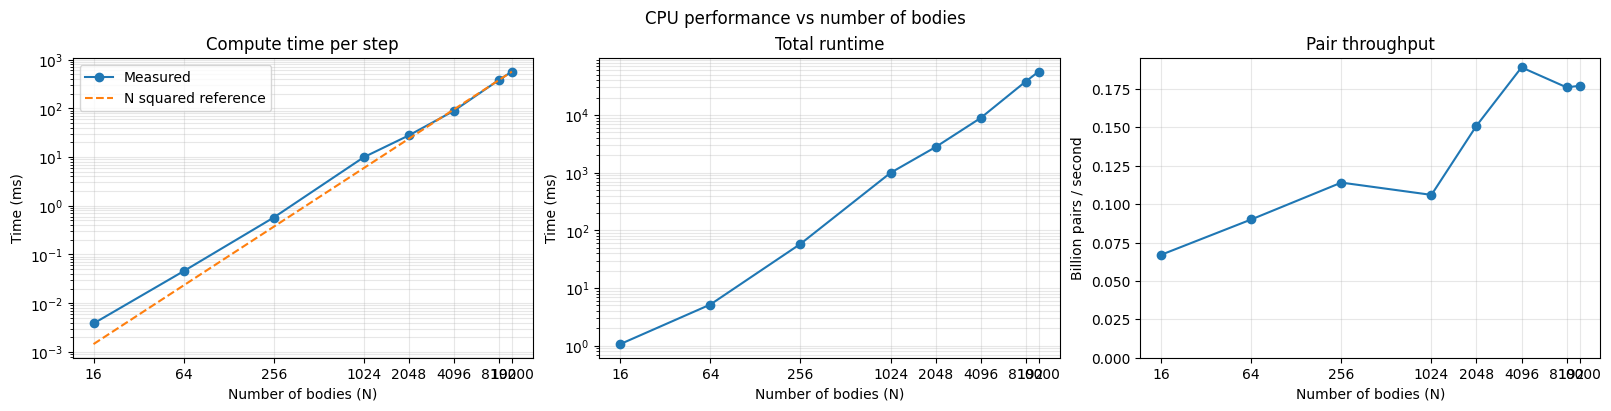

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
plots = [
    ("ms per step", "Compute time per step", "Time (ms)"),
    ("total ms", "Total runtime", "Time (ms)"),
    ("billion pairs per sec", "Pair throughput", "Billion pairs / second"),
]

for ax, (metric, title, ylabel) in zip(axes, plots):
    ax.plot(dataframe["bodies"], dataframe[metric], marker="o", label="Measured")
    ax.set_xscale("log", base=2)
    ax.set_xticks(dataframe["bodies"], labels=dataframe["bodies"].astype(str))
    ax.set_xlabel("Number of bodies (N)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, which="both", alpha=0.3)

for ax in axes[:2]:
    ax.set_yscale("log")

reference = dataframe["ms per step"].iloc[-1] * (
    dataframe["bodies"] / dataframe["bodies"].iloc[-1]
) ** 2
axes[0].plot(dataframe["bodies"], reference, "--", label="N squared reference")
axes[0].legend()
axes[2].set_ylim(bottom=0)
fig.suptitle("CPU performance vs number of bodies")
plt.show()